# Phase I. Non-AI Subgroup

In [5]:
from utils import (
    load_cellpose_model,
    inference,
    map_cell_instances,
    aggregate_cell_results,
    plot_cell_results,
    plot_dependence
    )

import pandas as pd
from matplotlib import pyplot as plt

PATH_TO_CELLS_CSV = '../combined_segmentation_quality_per_cell_v2.csv'

model = load_cellpose_model()

## 1. Example of Preprocessing Pipeline

Just an example of how inference quality statistics was collected.

,0
image_id,500
dataset,official
model,cpsam_v2
n_true,88
n_predicted,82
count_error,-6
TP,79
FP,3
FN,9
precision,0.963415


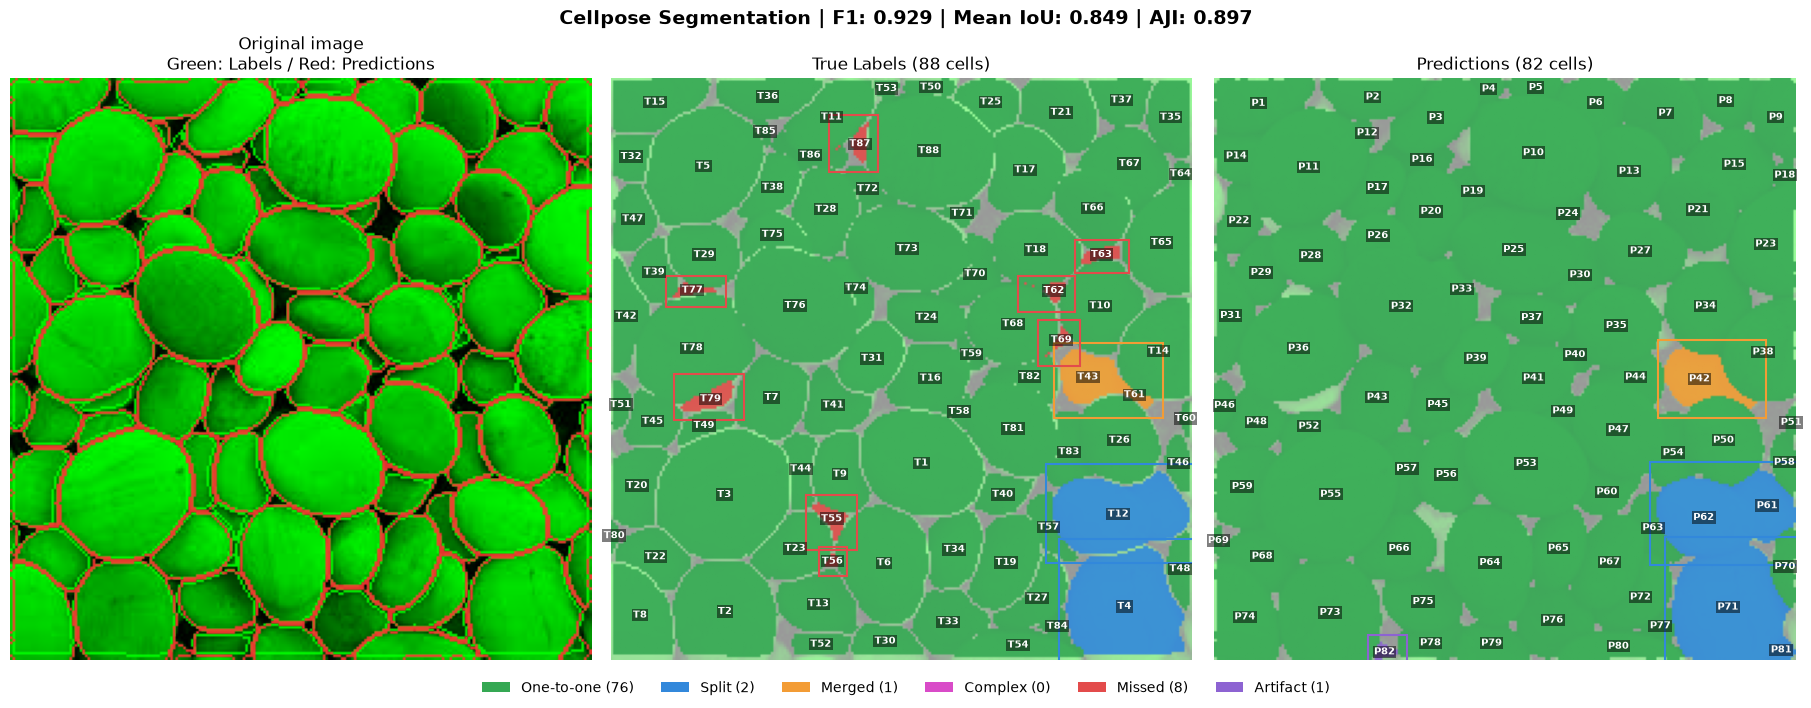

In [6]:
image, true_cells, predicted_cells = inference(
    model=model,
    path_to_image="../official_dataset/train/500_img.png",
    path_to_mask="../official_dataset/train/500_masks.png"
)

result = map_cell_instances(
    true_cells,
    predicted_cells,
    min_overlap=0.3,
    match_iou=0.5
)

summary = aggregate_cell_results(
    true_cells,
    predicted_cells,
    result,
    image_id="500",
    dataset="official",
    model="cpsam_v2"
)

display(summary.T)

fig, axes = plot_cell_results(
    image,
    true_cells,
    predicted_cells,
    result,
    summary=summary,
    show_ids=True,
    show_boxes=True,
    alpha=0.9,
)

## 2. Collecting Statistics

We assume that the preprocessing pipeline from the root directory (preprocessing_v2.ipynb) is already run and the CSV is ready for usage

In [7]:
cell_csv = pd.read_csv(PATH_TO_CELLS_CSV, index_col=0)
cell_csv

,pixel_area,min_x,min_y,max_x,max_y,centroid_x,centroid_y,perimeter,eccentricity,solidity,...,best_associated_iou,best_associated_overlap,assigned_pred_id,assigned_iou,is_TP,best_pred_id,best_iou,image_id,dataset,model
true_id,,,,,,,,,,,,,,,,,,,,,
1,1169.0,92,180,132,223,110.111206,198.530368,140.568542,0.681476,0.924111,...,0.833471,0.958294,1.0,0.833471,True,1,0.833471,official_dataset/train/164_img.png,official_dataset/train,cpsam_v2
2,540.0,90,222,124,246,105.068519,232.940741,99.112698,0.851400,0.897010,...,0.777583,0.934737,2.0,0.777583,True,2,0.777583,official_dataset/train/164_img.png,official_dataset/train,cpsam_v2
3,1382.0,169,152,215,196,192.824891,171.254703,148.260931,0.712227,0.954420,...,0.834483,0.946792,11.0,0.834483,True,11,0.834483,official_dataset/train/164_img.png,official_dataset/train,cpsam_v2
4,1145.0,213,136,248,188,230.144105,162.530131,148.367532,0.839799,0.896633,...,0.826733,0.937325,18.0,0.826733,True,18,0.826733,official_dataset/train/164_img.png,official_dataset/train,cpsam_v2
5,643.0,237,119,265,151,252.143079,134.024883,100.526912,0.758760,0.908192,...,0.815977,0.907937,21.0,0.815977,True,21,0.815977,official_dataset/train/164_img.png,official_dataset/train,cpsam_v2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43,953.0,36,1177,74,1212,53.651626,1193.780693,115.639610,0.348415,0.966531,...,0.899699,0.953241,2.0,0.899699,True,2,0.899699,flow_chamber_dataset/training_dataset/training...,flow_chamber_dataset/training_dataset/training...,cpsam_v2
44,998.0,97,1168,135,1201,116.014028,1184.186373,115.740115,0.512671,0.977473,...,0.897205,0.996994,5.0,0.897205,True,5,0.897205,flow_chamber_dataset/training_dataset/training...,flow_chamber_dataset/training_dataset/training...,cpsam_v2
45,472.0,165,1359,188,1385,175.627119,1370.506356,78.769553,0.484511,0.979253,...,0.917339,0.963983,7.0,0.917339,True,7,0.917339,flow_chamber_dataset/training_dataset/training...,flow_chamber_dataset/training_dataset/training...,cpsam_v2


## 3. Plotting

variables to choose from:
- 'pixel_area'
- 'perimeter'
- 'eccentricity'
- 'solidity',
- 'extent'
- 'orientation', 
- 'equivalent_diameter'
- 'aspect_ratio'
- 'circularity',
- 'pseudo_radius',

Targets to choose from
- 'n_associated_pred'
- 'n_associated_true'
- 'matched'
- 'split'
- 'merged'
- 'complex'
- 'missed',
- 'best_associated_iou'
- 'best_associated_overlap'
- 'assigned_iou'
- 'is_TP'
- 'best_iou'

### 3.1 Grid Overview of Dependences

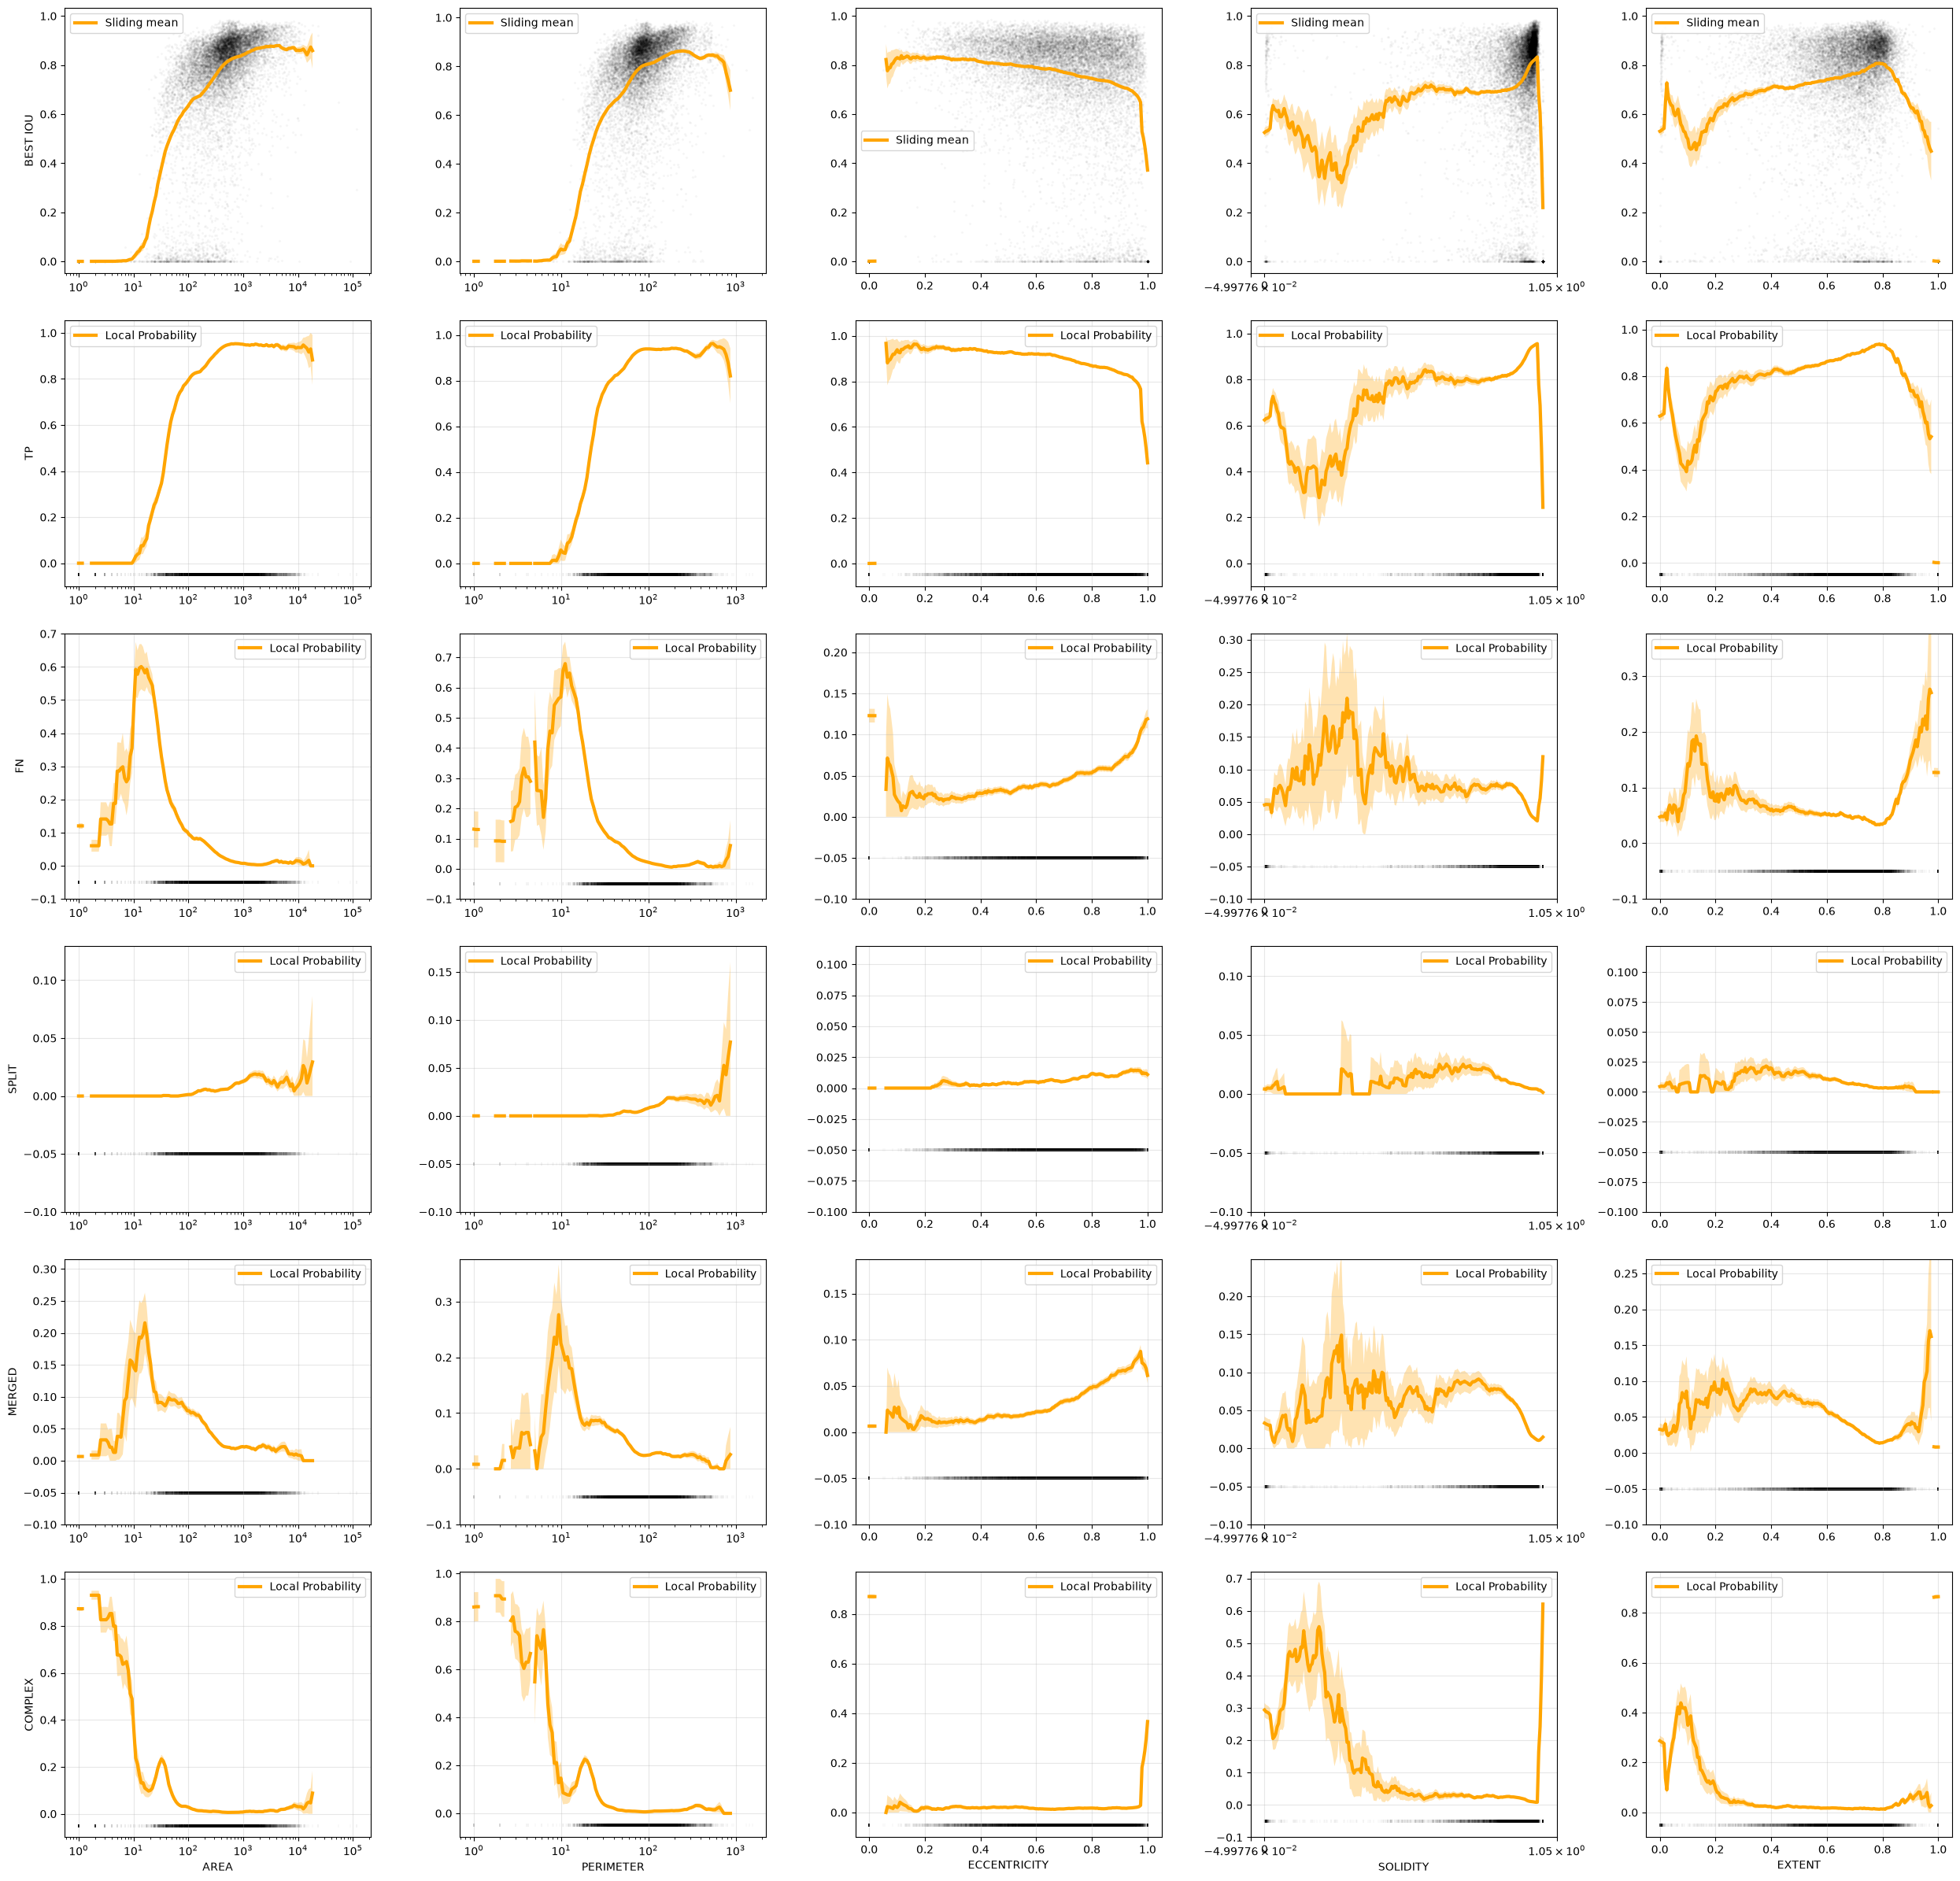

In [ ]:
variables = {
    "pixel_area": {"scale": "log", "window_size": 0.15, "name": "AREA"},
    "perimeter": {"scale": "log", "window_size": 0.12, "name": "PERIMETER"},
    "eccentricity": {"scale": "linear", "window_size": 0.05, "name": "ECCENTRICITY"},
    "solidity": {"scale": "symlog", "window_size": 0.04, "name": "SOLIDITY"},
    "extent": {"scale": "linear", "window_size": 0.04, "name": "EXTENT"},
}

targets = {
    "best_iou": {"scale": "linear", "boolean": False, "name": "BEST IOU"},
    "matched": {"scale": "linear", "boolean": True, "name": "TP"},
    "missed": {"scale": "linear", "boolean": True, "name": "FN"},
    "split": {"scale": "linear", "boolean": True, "name": "SPLIT"},
    "merged": {"scale": "linear", "boolean": True, "name": "MERGED"},
    "complex": {"scale": "linear", "boolean": True, "name": "COMPLEX"},
}

fig, axs = plt.subplots(
    nrows=len(targets),
    ncols=len(variables),
    figsize=(5 * len(variables), 4 * len(targets)),
    squeeze=False,
    constrained_layout=True,
)

for row, (target, target_cfg) in enumerate(targets.items()):

    for col, (variable, variable_cfg) in enumerate(variables.items()):

        ax = axs[row, col]

        plot_dependence(
            df=cell_csv,
            variable=variable,
            target=target,
            ax=ax,
            scale_x=variable_cfg["scale"],
            scale_y=target_cfg["scale"],
            window_size=variable_cfg["window_size"], # width of a kernel
            confidence_interval=True,
            boolean_mode=target_cfg["boolean"], # toggle to activate boolean mode
            scatter_subsample=0.1, # fraction of data to plot
            scatter_alpha=0.025,
            convolve_steps=200, # kernel steps
            min_samples=30, # minimum number of samples in the window to consider well-defined
            scatter_size=10 if target_cfg["boolean"] else 2,
            xlabel=variable_cfg["name"],
            ylabel=target_cfg["name"]
        )


        ax.set_title("")
        if row != len(targets) - 1:
            ax.set_xlabel("")
        if col != 0:
            ax.set_ylabel("")

plt.show()

### 3.2 Closer Look at Selected Pairs

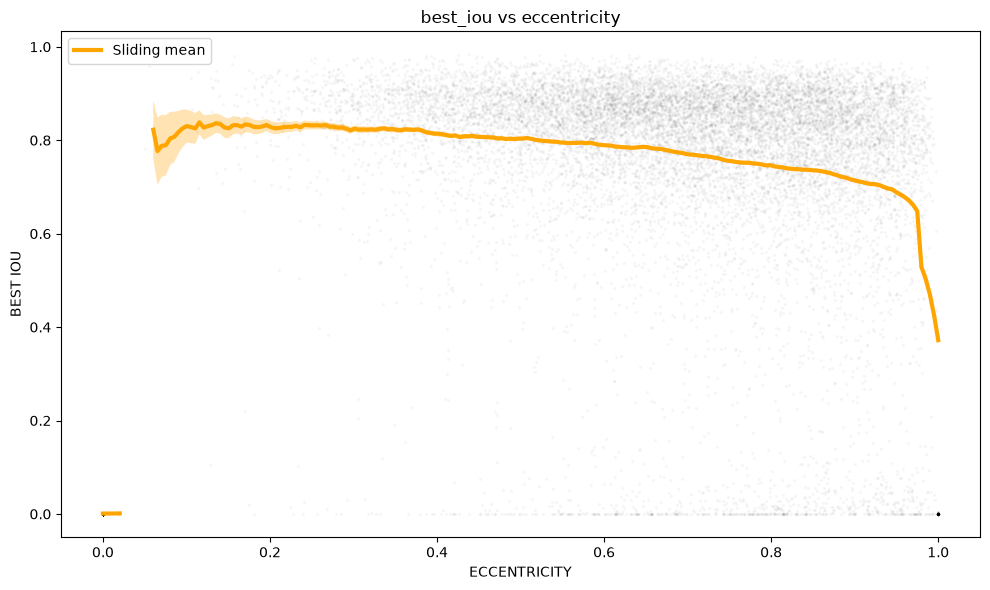

In [26]:
target = 'best_iou'
variable = 'eccentricity'

target_cfg = targets[target]
variable_cfg = variables[variable]

plot_dependence(
    df=cell_csv,
    variable=variable,
    target=target,
    scale_x=variable_cfg["scale"],
    scale_y=target_cfg["scale"],
    window_size=variable_cfg["window_size"],
    confidence_interval=True,
    boolean_mode=target_cfg["boolean"],
    scatter_subsample=0.1, # fraction of data to plot
    scatter_alpha=0.025,
    convolve_steps=200, # kernel steps
    min_samples=30,
    scatter_size=30 if target_cfg["boolean"] else 2,
    xlabel=variable_cfg["name"],
    ylabel=target_cfg["name"]
);

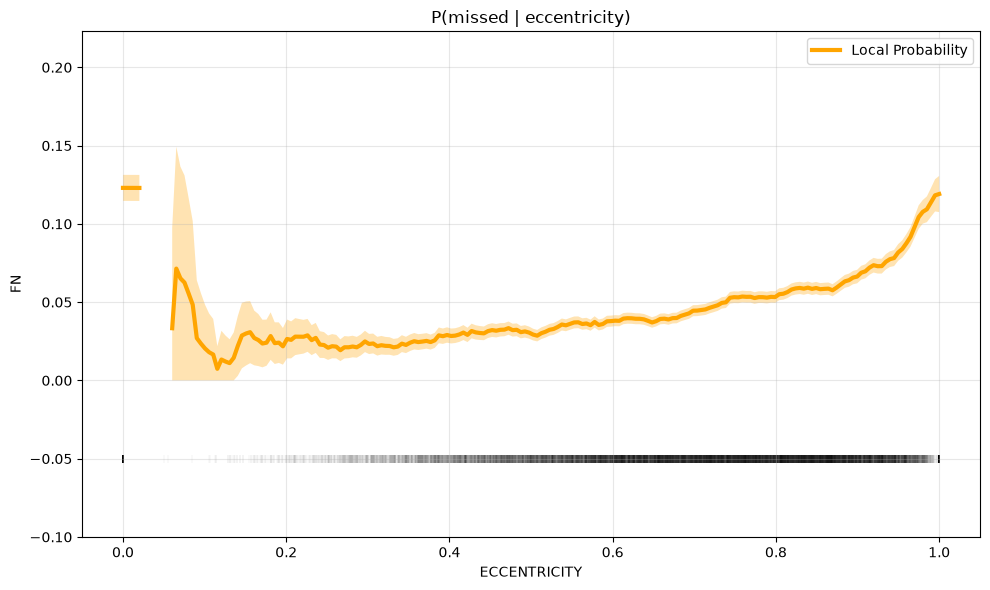

In [27]:
target = 'missed'
variable = 'eccentricity'

target_cfg = targets[target]
variable_cfg = variables[variable]

plot_dependence(
    df=cell_csv,
    variable=variable,
    target=target,
    scale_x=variable_cfg["scale"],
    scale_y=target_cfg["scale"],
    window_size=variable_cfg["window_size"],
    confidence_interval=True,
    boolean_mode=target_cfg["boolean"],
    scatter_subsample=0.1, # fraction of data to plot
    scatter_alpha=0.025,
    convolve_steps=200, # kernel steps
    min_samples=30,
    scatter_size=30 if target_cfg["boolean"] else 2,
    xlabel=variable_cfg["name"],
    ylabel=target_cfg["name"]
);

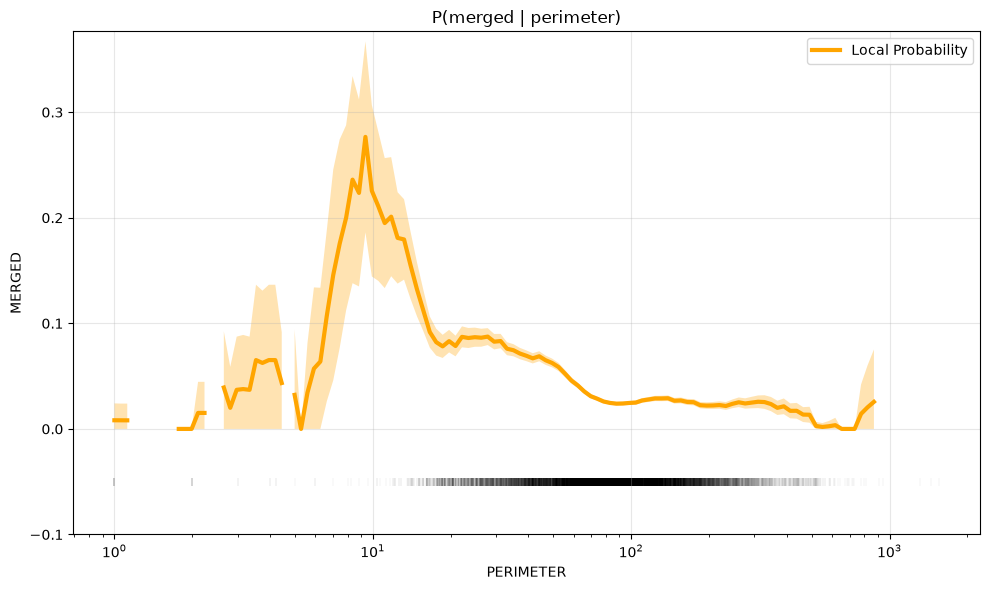

In [28]:
target = 'merged'
variable = 'perimeter'

target_cfg = targets[target]
variable_cfg = variables[variable]

plot_dependence(
    df=cell_csv,
    variable=variable,
    target=target,
    scale_x=variable_cfg["scale"],
    scale_y=target_cfg["scale"],
    window_size=variable_cfg["window_size"],
    confidence_interval=True,
    boolean_mode=target_cfg["boolean"],
    scatter_subsample=0.1, # fraction of data to plot
    scatter_alpha=0.025,
    convolve_steps=200, # kernel steps
    min_samples=30,
    scatter_size=30 if target_cfg["boolean"] else 2,
    xlabel=variable_cfg["name"],
    ylabel=target_cfg["name"]
);

Observations:

- Most noticeable fluctuations are observed in regions with few datapoints;
- Confidence interval of mean in dense regions are negligeably small;
- Intersection Over Union reaches the highest results on averahe when the cell's area and perimeter are in the most common value range (not too small or too large). This might be a specificity of model behaviour but it is also likely that certain range of cell areas correlate with other features of the images themselves;
- ECCENTRICITY shows the most stable pattern and importantly - in the regions with dense instances: Probability of a true cell being identified correctly decreases with increase in eccentricity. Conversely, the chance of true cell being missidentified (missed, merged or split) increases with higher cell eccentricity.